# Transfer learning

Korišćenje pretreniranih modela je veoma moćno, ali nekada ne rada tačno ono što nama treba. U ovom *notebook*-u ćemo naučiti *transfer learning* tehniku koja nam omogućava da podesimo pretrenirani model specifičnom problemu. U *transfer learning*-u, krećemo od pretreniranog modela i re-treniramo ga na zadatku koji se donekle preklapa sa orginalnim zadatkom za koji je model treniran. 

Na primer, imamo pretrenirani model koji je veoma dobar u prepoznavanju različitih tipova kola, a želimo da treniramo model koji raspoznaje različite tipove motocikala. Mnoge stvar koji je originalni model već naučio (npr. prepoznavanje točkova) će biti korisne i u novom kontekstu.

*Transfer learning* je posebno pogodan kada za naš specifičan problem nemamo velik i raznovrstan skup podataka. U ovom slučaju, treniranje modela od nule bi verovatno rezultovalo *overfitting*-om, ondosno lošom generalizacijom na nove podatke. *Transfer learning* nam povećava šanse da treniramo robustan model visokih performansi na malom skupu podataka.

Ciljevi *notebook*-a:
* Priprema modela za *transfer learning*
* Izvršavanje *transfer learning*-a da se pretrenirani model prilagodi našem malom skupu podataka
* Dalji *fine-tuning* modela za još veće unapređenje performansi.

## Personalizovana vratanca za Veljka-Debeljka
U prethodnom *notebook*-u smo trenirali model da raspoznaje mačke, pse i druge životinje. U ovom *notebook*-u ćemo personalizovati vratanca da prepoznaju Veljka-Debeljka. Veljkove slike se nalaze u direktorijumu `veljko-debeljko`.

Izazov je što pretrenirani model nije treniran da prepoznaje Veljka-Debeljka, a na raspolaganju imamo samo 30 Veljkovih slika. Ako bismo pokušali da treniramo model od početka, korišćenjem samo ovih 30 slika, taj model bi bio *overfit*-ovan. Zato ćemo koristiti *transfer learning*.

## Učitavanje pretreniranog modela
U prethodnom *notebook*-u smo učitali model koji je na izlazu imao *Dense* sloj od 1000 neurona. Međutim, sada želimo da pravimo binarnu odluku (jeste ili nije Veljko-Debeljko). Zato ćemo ukloniti izlazni (klasifikacioni) sloj modela. Ovo možemo uraditi postavkom *flag*-a `include_top=False` prilikom učitavanja modela. Nakon uklanjanja originalnog izlaznog sloja možemo dodati nove slojeve koji će rezultovazo klasifikacijom koju želimo.

In [1]:
from tensorflow import keras

base_model = keras.applications.VGG16(
    weights='imagenet',  # Load weights pre-trained on ImageNet.
    input_shape=(224, 224, 3),
    include_top=False)

58889256/58889256 [==============================] - 3s 0us/step


In [2]:
base_model.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

## Zamrzavanje osnovnog modela

Pre nego što dodamo nove slojeve, "zamrznućemo" pretrenirane slojeve modela. Težine "zamrznutih" slojeva nećemo ažurirati prilikom treniranja. Ažuriraćemo isključivo težine slojeva koje ćemo dodati na kraj modela radi klasifikacije. Kasnije (kada budemo radili *fine-tuning*) ćemo razmotriti ažuriranje ovih težina.

In [3]:
base_model.trainable = False

## Dodavanje novih slojeva

Dodaćemo dva sloja: pooling sloj i izlazni (klasifikacioni) sloj.

In [4]:
inputs = keras.Input(shape=(224, 224, 3))
# Separately from setting trainable on the model, we set training to False 
x = base_model(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
# A Dense classifier with a single unit (binary classification)
outputs = keras.layers.Dense(1)(x)
model = keras.Model(inputs, outputs)

In [5]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 vgg16 (Functional)          (None, 7, 7, 512)         14714688  
                                                                 
 global_average_pooling2d (G  (None, 512)              0         
 lobalAveragePooling2D)                                          
                                                                 
 dense (Dense)               (None, 1)                 513       
                                                                 
Total params: 14,715,201
Trainable params: 513
Non-trainable params: 14,714,688
_________________________________________________________________


Vidimo da nam `summary` prikazuje vgg16 pretrenirani model kao jednu celinu, bez prikazivanja interne strukture. Takođe možemo primetiti da imamo dosta *non-trainable* parametara kao posledicu zamrzavanja pretreniranog modela.

Kao i ranije, moramo kompajlirati model pri čemu specificiramo funkciju gubitka i metrike koje pratimo tokom treninga. Ranije smo kao metriku koristili *categorical crossentropy* jer smo imali više kategorija. Sada, pošto pravimo binarnu klasifikacionu odluku, ćemo koristiti [*binary crossentropy*](https://www.tensorflow.org/api_docs/python/tf/keras/losses/BinaryCrossentropy). Detalje razlike možete videti [ovde](https://gombru.github.io/2018/05/23/cross_entropy_loss/). Takođe ćemo koristiti* binary accuracy* umesto standardnog *accuracy* za praćenje procesa treniranja. Postavkom` from_logits=True` informišemo funkciju gubitka da izlazne vrednosti nisu normalizovene (npr., primenom *softmax*-a).

In [6]:
# Important to use binary crossentropy and binary accuracy as we now have a binary classification problem
model.compile(loss=keras.losses.BinaryCrossentropy(from_logits=True), metrics=[keras.metrics.BinaryAccuracy()])

## Augmentovanje podataka

Pošto radimo sa izuzetno malim trening skupom, posebno je važno da augmentujemo podatke. Ovo će omogućiti modelu da prepoznaje nove slike Veljka-Debeljka umesto da memoriše samo slike na kojima je istreniran.

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create a data generator
datagen_train = ImageDataGenerator(
    samplewise_center=True,  # set each sample mean to 0
    rotation_range=10,  # randomly rotate images in the range (degrees, 0 to 180)
    zoom_range=0.1,  # Randomly zoom image
    width_shift_range=0.1,  # randomly shift images horizontally (fraction of total width)
    height_shift_range=0.1,  # randomly shift images vertically (fraction of total height)
    horizontal_flip=True,  # randomly flip images
    vertical_flip=False,
)  # we don't expect Veljko to be upside-down so we will not flip vertically

# No need to augment validation data
datagen_valid = ImageDataGenerator(samplewise_center=True)

## Učitavanje podataka

Do sada smo videli:
* Učitavanje skupa podataka direktno kroz Keras biblioteku (što možemo za neke tipične skupove podataka kao što je MNIST)
* Učitavanje CSV skupa podataka (ASL dataset)

Za ovaj problem smo organizovali podatke u 3 direktorijuma: `train`, `validation` i `test`. Svaki od ovih direktorijuma ima 2 pod-direktorijuma `veljko` (sa slikama Veljka-Debeljka) `nije_veljko` (sa slikama drugih pasa i mačaka). Nije loše da (ručno) pogledate kako izgledaju slike da biste se upoznali sa specifičnostima skupa podataka.

Slike možemo učitati iz direktorijuma korišćenjem *Keras*-ove [`flow_from_directory`](https://keras.io/api/preprocessing/image/) funkcije. Primetite parametar `target_size` koji automatsko podešava da učitane slike budu veličine 224 x 224 x 3. 





In [18]:
# load and iterate training dataset
train_it = datagen_train.flow_from_directory(
    "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/train/",
    target_size=(224, 224),
    color_mode="rgb",
    class_mode="binary",
    batch_size=8,
)

# load and iterate validation dataset
valid_it = datagen_valid.flow_from_directory(
    "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/valid/",
    target_size=(224, 224),
    color_mode="rgb",
    class_mode="binary",
    batch_size=8,
)

Found 139 images belonging to 2 classes.
Found 31 images belonging to 2 classes.


## Treniranje modela

Ne zaboravite da moramo podesiti `steps_per_epoch` parametar jer (augmentacijom) možemo da proizvedemo beskonačno slika.

In [9]:
history = model.fit(train_it, steps_per_epoch=12, validation_data=valid_it, validation_steps=4, epochs=20)

Epoch 1/20
12/12 [==============================] - 53s 4s/step - loss: 1.6004 - binary_accuracy: 0.6374 - val_loss: 1.2130 - val_binary_accuracy: 0.6774
Epoch 2/20
12/12 [==============================] - 4s 354ms/step - loss: 0.7447 - binary_accuracy: 0.8542 - val_loss: 0.8594 - val_binary_accuracy: 0.7742
Epoch 3/20
12/12 [==============================] - 2s 147ms/step - loss: 0.6696 - binary_accuracy: 0.7582 - val_loss: 0.5981 - val_binary_accuracy: 0.8065
Epoch 4/20
12/12 [==============================] - 2s 141ms/step - loss: 0.5993 - binary_accuracy: 0.8462 - val_loss: 0.3234 - val_binary_accuracy: 0.8710
Epoch 5/20
12/12 [==============================] - 2s 140ms/step - loss: 0.4494 - binary_accuracy: 0.8681 - val_loss: 0.1924 - val_binary_accuracy: 0.9032
Epoch 6/20
12/12 [==============================] - 2s 140ms/step - loss: 0.4611 - binary_accuracy: 0.8352 - val_loss: 0.3122 - val_binary_accuracy: 0.8710
Epoch 7/20
12/12 [==============================] - 2s 148ms/step 

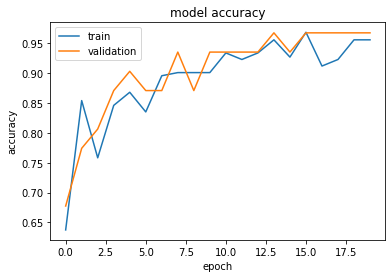

In [10]:
import matplotlib.pyplot as plt
plt.plot(history.history['binary_accuracy'])
plt.plot(history.history['val_binary_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

### Diskusija rezultata

Vidimo da su i trening i validaciona tačnost prilično visoke! Uspeli smo da na veoma malom skupu podataka dobijemo veoma dobre performanse zahvaljujući transferu znanja. Međutim, pokušaćemo da još malo unapredimo ove performanse.

## *Fine-tuning* modela

Možemo pokušati da još malo unapredimo performanse procesom *fine-tuning*-a već istreniranog modela. Da bismo ovo uradili "odmrznućemo" slojeve koje smo ranije zamrzli i ponovo trenirati model koristeći veoma nizak *learning rate*. Ovo će učiniti da osnovni pre-trenirani slojevi budu malo usavršavani u veoma malim koracima, što će doneti neko manje uvećanje performansi.

Važno: primenjujte ovaj korak samo kada je model sa "zamrznutim" slojevima već potpuno treniran. (Netrenirani) slojevi koje smo mi dodali na model su bili inicijalizovani nasumičnim težinama. Ovo znači da moraju biti ažurirani u velikoj meri da bi korektno klasifikovali slike. Da nismo držali originalne (pre-trenirane) VGG slojeve "zamrznute", inicijalna velika ažuriranja poslednjih slojeva bi potencijalno uzrokovala velika ažuriranja i u pre-treniranim slojevima. Ovo bi možda poremetilo važna pre-trenirana obeležja. Međutim, kada su novododati krajnji slojevi trenirani i iskonvergirali, dodatna ažuriranja modela u celini će biti znatno manja (pogotovo ako koristimo mali *learning rate*) i neće uništiti obeležja iz početnih slijeva.

U sledećem kodu ćemo pokušati da "odmrznemo" pretrenirane slojeve i *fine-tune*-ujemo model:

In [11]:
# Unfreeze the base model
base_model.trainable = True

# It's important to recompile your model after you make any changes
# to the `trainable` attribute of any inner layer, so that your changes
# are taken into account
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate = .00001),  # Very low learning rate
              loss=keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[keras.metrics.BinaryAccuracy()])

In [12]:
history1= model.fit(train_it, steps_per_epoch=12, validation_data=valid_it, validation_steps=4, epochs=20)

Epoch 1/20
12/12 [==============================] - 8s 325ms/step - loss: 0.2835 - binary_accuracy: 0.9231 - val_loss: 0.1004 - val_binary_accuracy: 0.9355
Epoch 2/20
12/12 [==============================] - 3s 253ms/step - loss: 0.0505 - binary_accuracy: 0.9890 - val_loss: 0.0444 - val_binary_accuracy: 0.9677
Epoch 3/20
12/12 [==============================] - 3s 210ms/step - loss: 0.0612 - binary_accuracy: 0.9670 - val_loss: 0.3060 - val_binary_accuracy: 0.9355
Epoch 4/20
12/12 [==============================] - 3s 214ms/step - loss: 0.0812 - binary_accuracy: 0.9670 - val_loss: 0.0090 - val_binary_accuracy: 1.0000
Epoch 5/20
12/12 [==============================] - 3s 196ms/step - loss: 0.0189 - binary_accuracy: 0.9896 - val_loss: 0.0035 - val_binary_accuracy: 1.0000
Epoch 6/20
12/12 [==============================] - 3s 208ms/step - loss: 0.0020 - binary_accuracy: 1.0000 - val_loss: 0.0051 - val_binary_accuracy: 1.0000
Epoch 7/20
12/12 [==============================] - 3s 233ms/ste

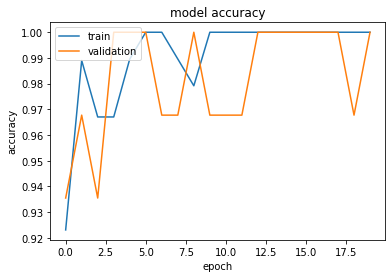

In [13]:
import matplotlib.pyplot as plt
plt.plot(history1.history['binary_accuracy'])
plt.plot(history1.history['val_binary_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

## Analiza grešaka modela

Za detaljnije instrukcije o načinu analize grešaka modela preporučujem https://github.com/ajaymache/machine-learning-yearning, poglavlja 14 i 15. 

In [14]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing import image as image_utils
from tensorflow.keras.applications.imagenet_utils import preprocess_input

def show_image(image_path):
    image = mpimg.imread(image_path)
    plt.imshow(image)

def make_predictions(image_path):
    show_image(image_path)
    image = image_utils.load_img(image_path, target_size=(224, 224))
    image = image_utils.img_to_array(image)
    image = image.reshape(1,224,224,3)
    image = preprocess_input(image)
    preds = model.predict(image)
    return preds

In [15]:
def predict(image_path):
    preds = make_predictions(image_path)
    if preds[0] < 0:
        print("Veljko-Debeljko!")
    else:
        print("Nije Veljko-Debeljko :(")

### Validacioni skup

1/1 [==============================] - 0s 16ms/step


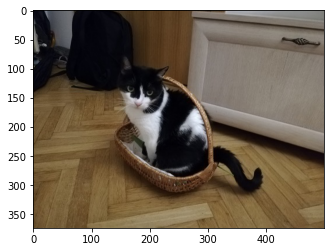

In [16]:
import os
directory = "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/valid/veljko"
for filename in os.listdir(directory):
    f = os.path.join(directory, filename)    
    if os.path.isfile(f):
        preds = make_predictions(f)
        if preds[0] > 0:
          show_image(f)

1/1 [==============================] - 0s 15ms/step


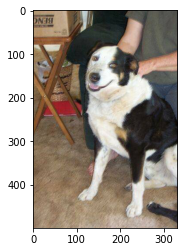

In [17]:
import os
directory = "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/valid/nije_veljko"
for filename in os.listdir(directory):
    f = os.path.join(directory, filename)    
    if os.path.isfile(f):
        preds = make_predictions(f)
        if preds[0] < 0:
          show_image(f)

### Test skup

1/1 [==============================] - 0s 15ms/step


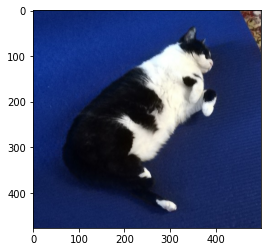

In [19]:
import os
directory = "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/test/veljko"
for filename in os.listdir(directory):
    f = os.path.join(directory, filename)    
    if os.path.isfile(f):
        preds = make_predictions(f)
        if preds[0] > 0:
          show_image(f)

1/1 [==============================] - 0s 15ms/step


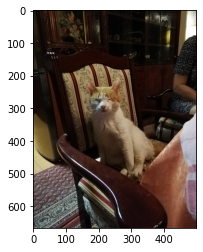

In [20]:
import os
directory = "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/test/nije_veljko"
for filename in os.listdir(directory):
    f = os.path.join(directory, filename)    
    if os.path.isfile(f):
        preds = make_predictions(f)
        if preds[0] < 0:
          show_image(f)